# 🛒 Sentiment Analysis on Product Reviews (Merch Sales)
Proyek ini bertujuan untuk mengklasifikasikan sentimen review produk berdasarkan rating bintang:
- **Bintang 1 - 2**: Review *Negative*
- **Bintang 3**: Review *Neutral*
- **Bintang 4 - 5**: Review *Positive* (Bagus)

Pipeline mencakup analisis sentimen per produk, deep cleaning teks, penyimpanan data terproses, serta pemodelan Transformer (BERT) end-to-end.

In [ ]:
# General Data Science & Visualization
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Text Preprocessing & Encoding
import re
import string
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

# PyTorch Deep Learning
import torch
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW

# HuggingFace Transformers
from transformers import BertTokenizer, BertForSequenceClassification

## 1. Memuat Dataset
Dataset `merch_sales.csv` dimuat menggunakan *relative path* fleksibel.

In [ ]:
data_path = "/content/merch_sales.csv" if os.path.exists("/content/merch_sales.csv") else "../data/raw/merch_sales.csv"
df = pd.read_csv(data_path)
print(f"Dataset berhasil dimuat! Dimensi data: {df.shape}")
df.head()

Dataset berhasil dimuat! Dimensi data: (7394, 15)


,Order ID,Order Date,Product ID,Product Category,Buyer Gender,Buyer Age,Order Location,International Shipping,Sales Price,Shipping Charges,Sales per Unit,Quantity,Total Sales,Rating,Review
0,189440,2024-07-21,BF1543,Clothing,Male,30,New Jersey,No,100,0,100,1,100,4,The delivery team handled the product with care.
1,187385,2024-07-20,BF1543,Clothing,Male,32,Las Vegas,No,100,0,100,1,100,3,Had slight delays but the product was in good ...
2,181844,2024-07-21,BF1544,Other,Female,26,Cardiff,Yes,9,40,49,1,49,2,Waste of Money.
3,197934,2024-08-19,BF1544,Other,Male,28,Pittsburgh,No,9,0,9,2,18,3,Had slight delays but the product was in good ...
4,122470,2024-01-06,BF1545,Other,Female,19,Miami,No,10,0,10,3,30,5,Lack of delivery delays is greatly appreciated.


In [ ]:
print("Informasi Dataset:")
df.info()
print("\nPengecekan Missing Values:")
print(df[['Product ID', 'Product Category', 'Rating', 'Review']].isna().sum())

Informasi Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7394 entries, 0 to 7393
Data columns (total 15 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   Order ID                7394 non-null   int64 
 1   Order Date              7394 non-null   object
 2   Product ID              7394 non-null   object
 3   Product Category        7394 non-null   object
 4   Buyer Gender            7394 non-null   object
 5   Buyer Age               7394 non-null   int64 
 6   Order Location          7394 non-null   object
 7   International Shipping  7394 non-null   object
 8   Sales Price             7394 non-null   int64 
 9   Shipping Charges        7394 non-null   int64 
 10  Sales per Unit          7394 non-null   int64 
 11  Quantity                7394 non-null   int64 
 12  Total Sales             7394 non-null   int64 
 13  Rating                  7394 non-null   int64 
 14  Review                  7394 non-null

## 2. Target Engineering: Konversi Bintang ke Sentimen
Sesuai kebutuhan:
- **Bintang 1 - 2** $\rightarrow$ **Negative**
- **Bintang 3** $\rightarrow$ **Neutral**
- **Bintang 4 - 5** $\rightarrow$ **Positive** (Review Bagus)

In [ ]:
def map_rating_to_sentiment(rating):
    if rating in [1, 2]:
        return 'Negative'
    elif rating == 3:
        return 'Neutral'
    elif rating in [4, 5]:
        return 'Positive'
    return 'Neutral'

df['Sentiment'] = df['Rating'].apply(map_rating_to_sentiment)

print("Distribusi Target Sentimen:")
print(df['Sentiment'].value_counts())
print("\nPersentase Sentimen:")
print(df['Sentiment'].value_counts(normalize=True) * 100)

Distribusi Target Sentimen:
Sentiment
Positive    4430
Negative    1847
Neutral     1117
Name: count, dtype: int64

Persentase Sentimen:
Sentiment
Positive    59.913443
Negative    24.979713
Neutral     15.106843
Name: proportion, dtype: float64


## 3. Analisis Sentimen per Produk & Kategori
Menganalisis distribusi sentimen dan performa review untuk setiap `Product ID` dan `Product Category`.

In [ ]:
# Analisis Sentimen Berdasarkan Kategori Produk
category_sentiment = pd.crosstab(df['Product Category'], df['Sentiment'], normalize='index') * 100
print("Persentase Sentimen per Kategori Produk (%):")
print(category_sentiment.round(2))

# Analisis Sentimen per Product ID
product_sentiment = pd.crosstab(df['Product ID'], df['Sentiment'])
product_sentiment['Total_Reviews'] = product_sentiment.sum(axis=1)
product_sentiment['Positive_Ratio (%)'] = (product_sentiment['Positive'] / product_sentiment['Total_Reviews'] * 100).round(2)
product_sentiment = product_sentiment.sort_values(by='Positive_Ratio (%)', ascending=False)

print("\nSentimen per Product ID (Diurutkan dari % Positif tertinggi):")
product_sentiment

Persentase Sentimen per Kategori Produk (%):
Sentiment         Negative  Neutral  Positive
Product Category                             
Clothing             24.57     15.6     59.83
Ornaments            26.86     14.8     58.33
Other                23.08     14.3     62.62

Sentimen per Product ID (Diurutkan dari % Positif tertinggi):


Sentiment,Negative,Neutral,Positive,Total_Reviews,Positive_Ratio (%)
Product ID,,,,,
BF1545,131,75,363,569,63.80
BF1555,31,18,84,133,63.16
BF1544,169,112,451,732,61.61
BF1550,176,118,456,750,60.80
BF1548,373,222,902,1497,60.25
BF1554,110,67,265,442,59.95
BF1543,165,124,432,721,59.92
BF1546,92,52,214,358,59.78
BF1547,80,56,190,326,58.28


/tmp/ipykernel_7113/2690774015.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Sentiment', palette=palette, ax=axes[0])


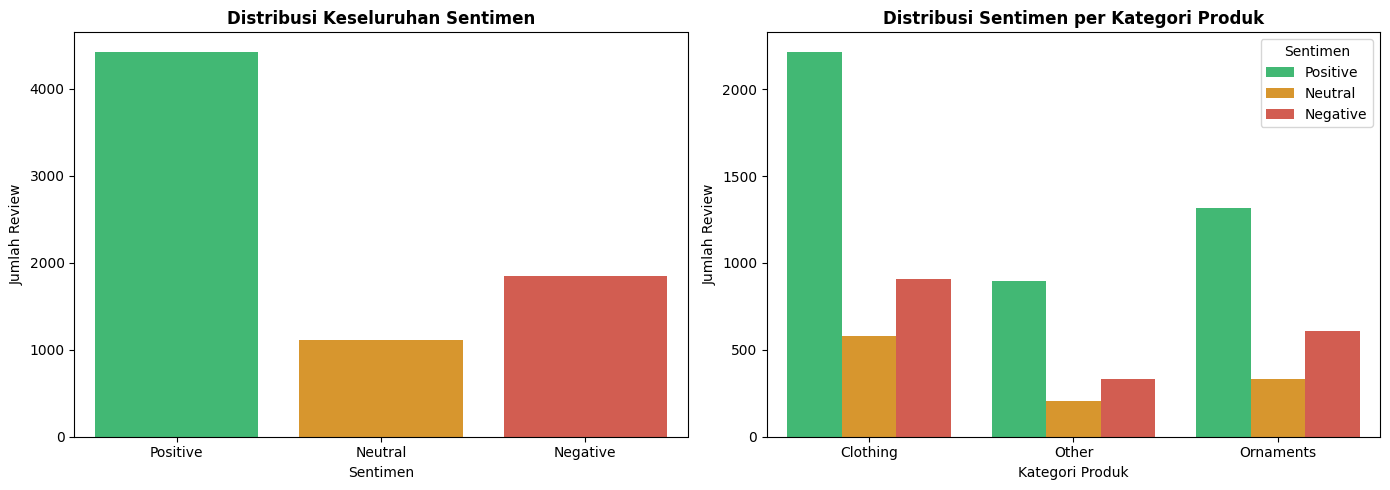

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Distribusi Sentimen Keseluruhan
palette = {'Negative': '#e74c3c', 'Neutral': '#f39c12', 'Positive': '#2ecc71'}
sns.countplot(data=df, x='Sentiment', palette=palette, ax=axes[0])
axes[0].set_title('Distribusi Keseluruhan Sentimen', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Sentimen')
axes[0].set_ylabel('Jumlah Review')

# Plot 2: Sentimen per Kategori Produk
sns.countplot(data=df, x='Product Category', hue='Sentiment', palette=palette, ax=axes[1])
axes[1].set_title('Distribusi Sentimen per Kategori Produk', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Kategori Produk')
axes[1].set_ylabel('Jumlah Review')
axes[1].legend(title='Sentimen')

plt.tight_layout()
plt.show()

## 4. Text Preprocessing (Deep Cleaning)
Pembersihan teks review berbahasa Inggris yang kompatibel dengan arsitektur Transformer (BERT):
- Menghapus URL/link
- Menghapus karakter non-ASCII
- Merapikan whitespace/spasi berlebih
- Normalisasi huruf kecil (lowercasing)

In [ ]:
def clean_review_text(text):
    if not isinstance(text, str):
        return ""
    # Hapus URL
    text = re.sub(r"http\S+|www\S+|https\S+", "", text, flags=re.MULTILINE)
    # Hapus karakter non-ASCII
    text = re.sub(r"[^\x00-\x7F]+", " ", text)
    # Rapikan spasi berlebih
    text = re.sub(r"\s\s+", " ", text)
    return text.strip().lower()

# Terapkan pembersihan teks menggunakan .apply()
df['Review_Cleaned'] = df['Review'].apply(clean_review_text)
df['Length_Text'] = df['Review_Cleaned'].apply(lambda x: len(x.split()))

# Tampilkan sampel perbandingan sebelum dan sesudah
df[['Review', 'Review_Cleaned', 'Length_Text', 'Sentiment']].head()

,Review,Review_Cleaned,Length_Text,Sentiment
0,The delivery team handled the product with care.,the delivery team handled the product with care.,8,Positive
1,Had slight delays but the product was in good ...,had slight delays but the product was in good ...,10,Neutral
2,Waste of Money.,waste of money.,3,Negative
3,Had slight delays but the product was in good ...,had slight delays but the product was in good ...,10,Neutral
4,Lack of delivery delays is greatly appreciated.,lack of delivery delays is greatly appreciated.,7,Positive


## 5. Menyimpan Data Bersih ke `data/processed/`
Menyimpan dataset yang telah melalui tahap feature engineering dan text deep cleaning.

In [ ]:
processed_dir = "data/processed" if os.path.exists("data/processed") else "../data/processed"
os.makedirs(processed_dir, exist_ok=True)

output_path = os.path.join(processed_dir, "merch_sales_cleaned.csv")
df.to_csv(output_path, index=False)
print(f"Data bersih berhasil disimpan ke: {output_path}")

Data bersih berhasil disimpan ke: ../data/processed/merch_sales_cleaned.csv


## 6. Dataset Splitting & Label Encoding
Memisahkan dataset menjadi 80% Data Latih (*Train*) dan 20% Data Uji (*Test*) dengan stratified sampling untuk menjaga proporsi kelas sentimen.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    df['Review_Cleaned'],
    df['Sentiment'],
    test_size=0.2,
    random_state=42,
    stratify=df['Sentiment']
)

# Label Encoding: Negative -> 0, Neutral -> 1, Positive -> 2
label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

print(f"Jumlah Data Latih : {len(X_train)}")
print(f"Jumlah Data Uji   : {len(X_test)}")
print("Pemetaan Label    :", dict(zip(label_encoder.classes_, range(len(label_encoder.classes_)))))

Jumlah Data Latih : 5915
Jumlah Data Uji   : 1479
Pemetaan Label    : {'Negative': 0, 'Neutral': 1, 'Positive': 2}


## 7. Tokenisasi BERT & PyTorch DataLoader

In [ ]:
tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')

def tokenize_data(texts, tokenizer, max_length=128):
    return tokenizer(
        list(texts),
        max_length=max_length,
        padding='max_length',
        truncation=True,
        return_tensors="pt"
    )

train_encodings = tokenize_data(X_train, tokenizer)
test_encodings = tokenize_data(X_test, tokenizer)

class ReviewSentimentDataset(Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        item = {key: val[idx] for key, val in self.encodings.items()}
        item['labels'] = torch.tensor(self.labels[idx], dtype=torch.long)
        return item

train_dataset = ReviewSentimentDataset(train_encodings, y_train_encoded)
test_dataset = ReviewSentimentDataset(test_encodings, y_test_encoded)

train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=16)

## 8. Pemodelan BERT (Fine-Tuning)

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device yang digunakan: {device}")

model = BertForSequenceClassification.from_pretrained('bert-base-uncased', num_labels=3)
optimizer = AdamW(model.parameters(), lr=5e-5)
model.to(device)

Device yang digunakan: cpu


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


BertForSequenceClassification(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): LayerNorm((768,), eps=1e-12,

## 9. Training Loop

In [ ]:
import os
from google.colab import drive
from google.colab import auth
auth.authenticate_user()
from tqdm.auto import tqdm

# 1. Mount Google Drive
drive.mount('/content/drive')

# 2. Tentukan folder penyimpanan di Google Drive
save_dir = '/content/drive/MyDrive/model_checkpoints'
os.makedirs(save_dir, exist_ok=True)

epochs = 3

for epoch in range(epochs):
    model.train()
    total_loss = 0

    progress_bar = tqdm(
        train_loader,
        desc=f"Epoch {epoch + 1}/{epochs}",
        leave=True
    )

    for batch in progress_bar:
        optimizer.zero_grad()

        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['labels'].to(device)

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels
        )

        loss = outputs.loss

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

        # Update progress bar dengan loss saat ini
        progress_bar.set_postfix(loss=f"{loss.item():.4f}")

    avg_loss = total_loss / len(train_loader)

    print(f"Epoch {epoch + 1}/{epochs} - Average Loss: {avg_loss:.4f}")

    # 3. Simpan Checkpoint ke Google Drive
    checkpoint_path = os.path.join(save_dir, f"checkpoint_epoch_{epoch + 1}.pt")

    torch.save({
        'epoch': epoch + 1,
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'loss': avg_loss,
    }, checkpoint_path)

    print(f"Checkpoint berhasil disimpan di: {checkpoint_path}")

Mounted at /content/drive


Epoch 1/3:   0%|          | 0/370 [00:00<?, ?it/s]

Epoch 1/3 - Average Loss: 0.0470
Checkpoint berhasil disimpan di: /content/drive/MyDrive/model_checkpoints/checkpoint_epoch_1.pt


Epoch 2/3:   0%|          | 0/370 [00:00<?, ?it/s]

Epoch 2/3 - Average Loss: 0.0004
Checkpoint berhasil disimpan di: /content/drive/MyDrive/model_checkpoints/checkpoint_epoch_2.pt


Epoch 3/3:   0%|          | 0/370 [00:00<?, ?it/s]

Epoch 3/3 - Average Loss: 0.0002
Checkpoint berhasil disimpan di: /content/drive/MyDrive/model_checkpoints/checkpoint_epoch_3.pt


## 10. Evaluasi Model pada Data Uji (Test Data)

=== Classification Report ===
              precision    recall  f1-score   support

    Negative       1.00      1.00      1.00       370
     Neutral       1.00      1.00      1.00       223
    Positive       1.00      1.00      1.00       886

    accuracy                           1.00      1479
   macro avg       1.00      1.00      1.00      1479
weighted avg       1.00      1.00      1.00      1479



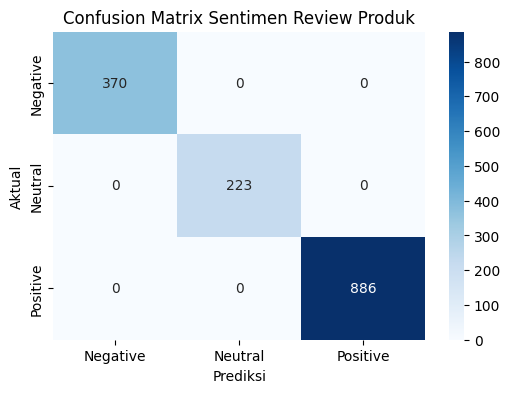

In [ ]:
model.eval()
all_preds, all_labels = [], []

with torch.no_grad():
    for batch in test_loader:
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['labels'].to(device)

        outputs = model(input_ids=input_ids, attention_mask=attention_mask)
        preds = torch.argmax(outputs.logits, dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

print("=== Classification Report ===")
print(classification_report(all_labels, all_preds, target_names=label_encoder.classes_))

# Confusion Matrix
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.title('Confusion Matrix Sentimen Review Produk')
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.show()

## 11. Menyimpan Model ke Folder `models/`
Model dan tokenizer disimpan ke folder `models/` agar dapat langsung diintegrasikan dengan aplikasi Streamlit (`app.py`).

In [ ]:
model_dir = "models" if os.path.exists("models") else "../models"
os.makedirs(model_dir, exist_ok=True)

model.save_pretrained(model_dir)
tokenizer.save_pretrained(model_dir)
print(f"Model dan Tokenizer berhasil disimpan di: {model_dir}")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model dan Tokenizer berhasil disimpan di: ../models


## 12. Uji Coba Inferensi (Prediksi Review Baru)

In [ ]:
def predict_product_review(review_text, model, tokenizer, label_encoder, device):
    cleaned = clean_review_text(review_text)
    inputs = tokenizer(
        cleaned,
        return_tensors="pt",
        truncation=True,
        padding="max_length",
        max_length=128
    )

    input_ids = inputs['input_ids'].to(device)
    attention_mask = inputs['attention_mask'].to(device)

    model.eval()
    with torch.no_grad():
        outputs = model(input_ids=input_ids, attention_mask=attention_mask)
        probs = torch.nn.functional.softmax(outputs.logits, dim=-1)
        pred_idx = torch.argmax(probs, dim=1).item()
        confidence = probs[0][pred_idx].item() * 100

    predicted_sentiment = label_encoder.inverse_transform([pred_idx])[0]
    return predicted_sentiment, confidence

# Pengujian dengan beberapa kalimat review produk
sample_reviews = [
    "The product arrived in perfect condition and the material is superb!",
    "Had slight delays but the product was in good shape.",
    "Completely useless item, broke on the first try and waste of money."
]

for sample in sample_reviews:
    sent, conf = predict_product_review(sample, model, tokenizer, label_encoder, device)
    print(f"Review : \"{sample}\"")
    print(f"Hasil  : {sent} (Keyakinan: {conf:.2f}%)\n")

Review : "The product arrived in perfect condition and the material is superb!"
Hasil  : Positive (Keyakinan: 99.98%)

Review : "Had slight delays but the product was in good shape."
Hasil  : Neutral (Keyakinan: 99.98%)

Review : "Completely useless item, broke on the first try and waste of money."
Hasil  : Negative (Keyakinan: 99.97%)

